In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the smaller dataset
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

toatlcharges column should be numeric but stored as string we should make it numeric

In [4]:
# Convert TotalCharges temporarily to numeric
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Identify values that could not be converted
invalid_values = df.loc[
    total_charges_numeric.isna(),
    "TotalCharges"
]

print("Invalid entries:", len(invalid_values))

print("\nInvalid values:")
print(invalid_values.value_counts())

print("\nFirst 10 original values:")
print(df["TotalCharges"].head(10))

Invalid entries: 11

Invalid values:
TotalCharges
    11
Name: count, dtype: int64

First 10 original values:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str


In [5]:
# Display rows where TotalCharges is missing or invalid
invalid_rows = df[
    pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
]

display(invalid_rows)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [6]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [7]:
print("Data type:", df["TotalCharges"].dtype)

print("Missing values:", df["TotalCharges"].isnull().sum())

print("\nAffected records after cleaning:")
display(df.loc[invalid_rows.index, ["tenure", "TotalCharges"]])

Data type: float64
Missing values: 0

Affected records after cleaning:


,tenure,TotalCharges
488,0,0.0
753,0,0.0
936,0,0.0
1082,0,0.0
1340,0,0.0
3331,0,0.0
3826,0,0.0
4380,0,0.0
5218,0,0.0
6670,0,0.0


In [8]:
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Exclude customerID because it is an identifier
categorical_columns.remove("customerID")

# Display unique values in each categorical column
for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].unique())
    print("Number of categories:", df[col].nunique())


gender
Unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Number of categories: 2

Partner
Unique values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Number of categories: 2

Dependents
Unique values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Number of categories: 2

PhoneService
Unique values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Number of categories: 2

MultipleLines
Unique values: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
Number of categories: 3

InternetService
Unique values: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
Number of categories: 3

OnlineSecurity
Unique values: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Number of categories: 3

OnlineBackup
Unique values: <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
Number of categories: 3

DeviceProtection
Unique values: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dt

In [9]:
# Numerical columns
numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Statistical summary
display(df[numerical_columns].describe())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


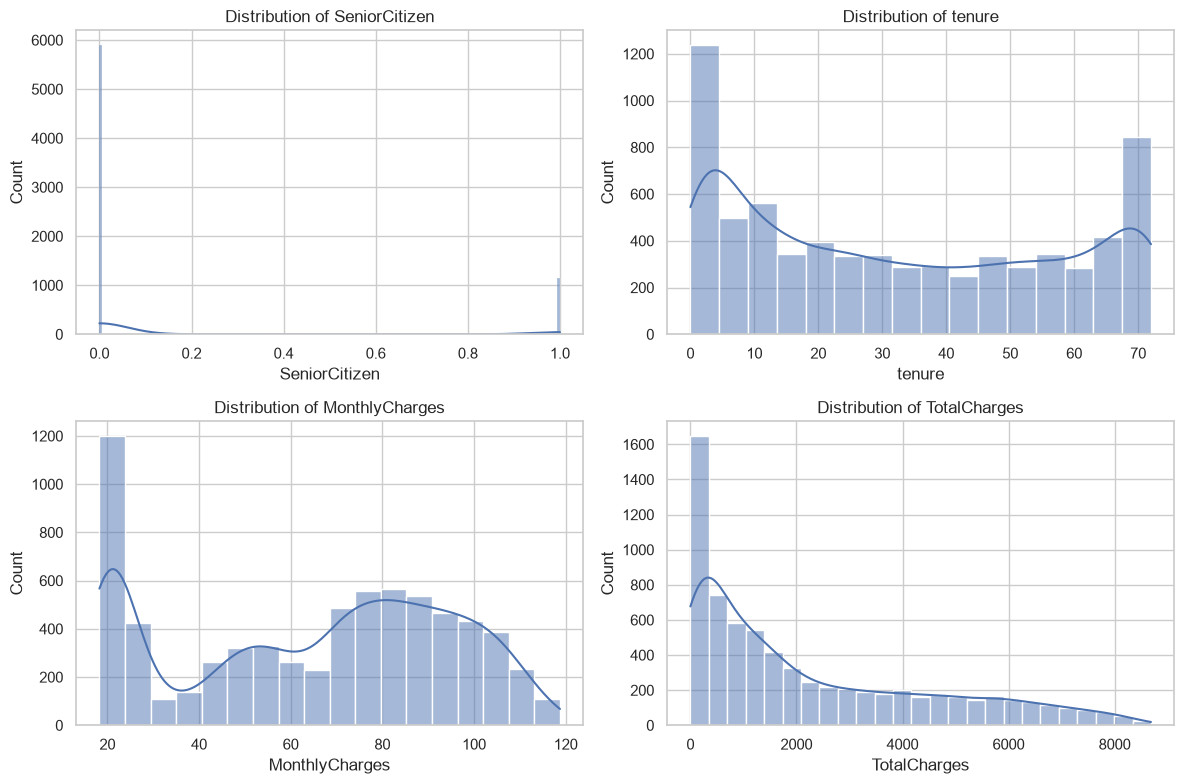

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(numerical_columns, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [11]:
# Convert churn into binary values temporarily for grouping
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Compare numerical feature averages by churn status
churn_comparison = df.groupby("Churn_Binary")[
    ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
].mean()

churn_comparison.index = ["Not Churned", "Churned"]

display(churn_comparison)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
Not Churned,37.569965,61.265124,2549.911442,0.128721
Churned,17.979133,74.441332,1531.796094,0.254682


In [12]:
churn_median = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].median()

display(churn_median)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


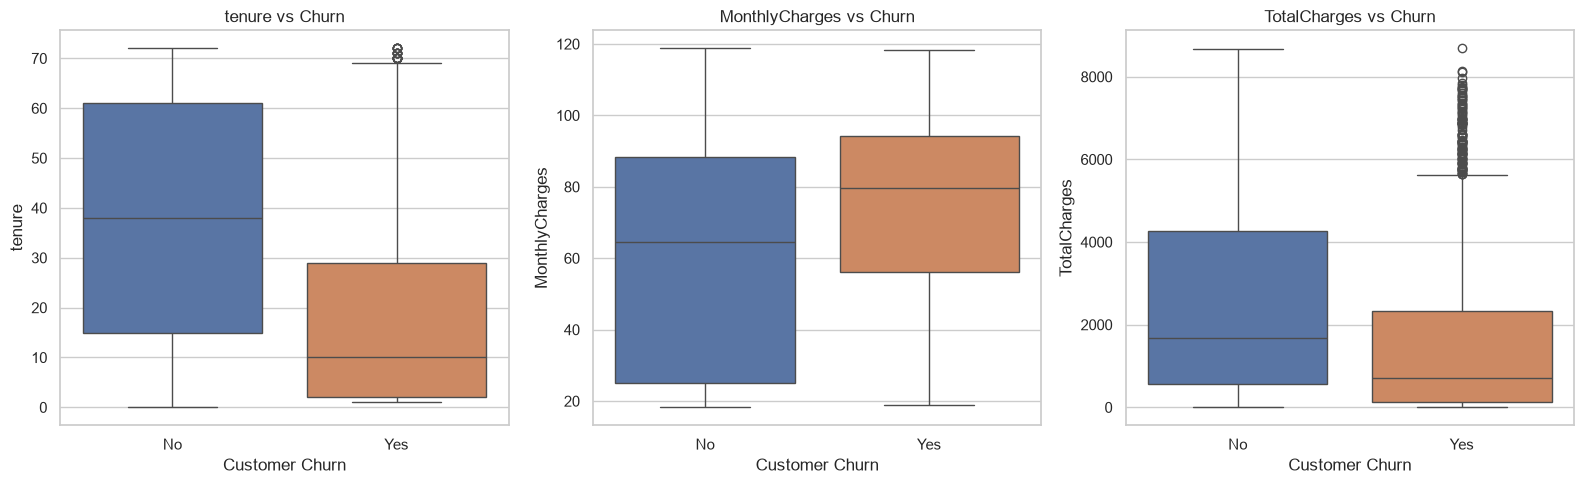

In [13]:
# Numerical features to compare
features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for feature, ax in zip(features, axes):
    sns.boxplot(
        data=df,
        x="Churn",
        y=feature,
        hue="Churn",
        ax=ax,
        legend=False
    )

    ax.set_title(f"{feature} vs Churn")
    ax.set_xlabel("Customer Churn")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


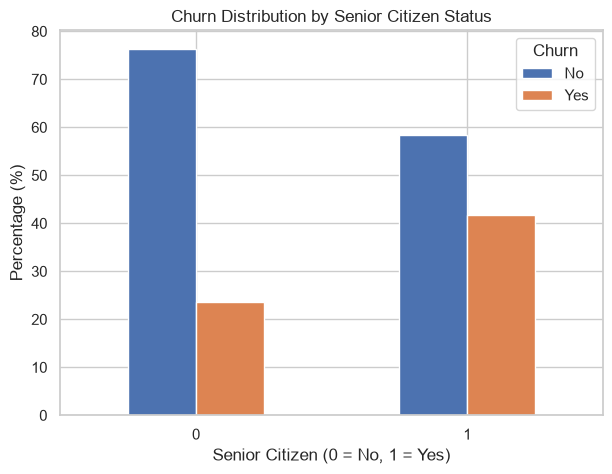

In [14]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

display(senior_churn)

senior_churn.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Distribution by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

Correlation with Churn:


,Correlation
tenure,-0.352229
TotalCharges,-0.198324
MonthlyCharges,0.193356
SeniorCitizen,0.150889


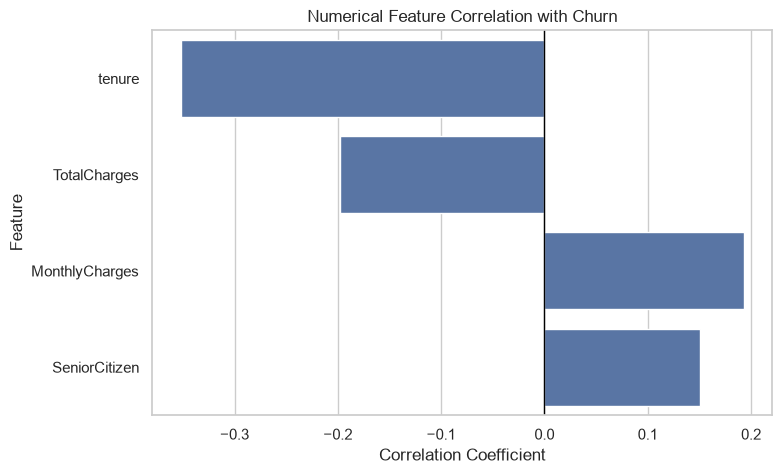

In [15]:
# Numerical features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Calculate correlation with churn
correlations = df[numerical_features + ["Churn_Binary"]].corr()

# Extract churn correlations
churn_correlation = (
    correlations["Churn_Binary"]
    .drop("Churn_Binary")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with Churn:")
display(churn_correlation.to_frame("Correlation"))

# Visualize correlation
plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_correlation.values,
    y=churn_correlation.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Numerical Feature Correlation with Churn")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.show()

In [ ]:
#contract length vs churn
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn)

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


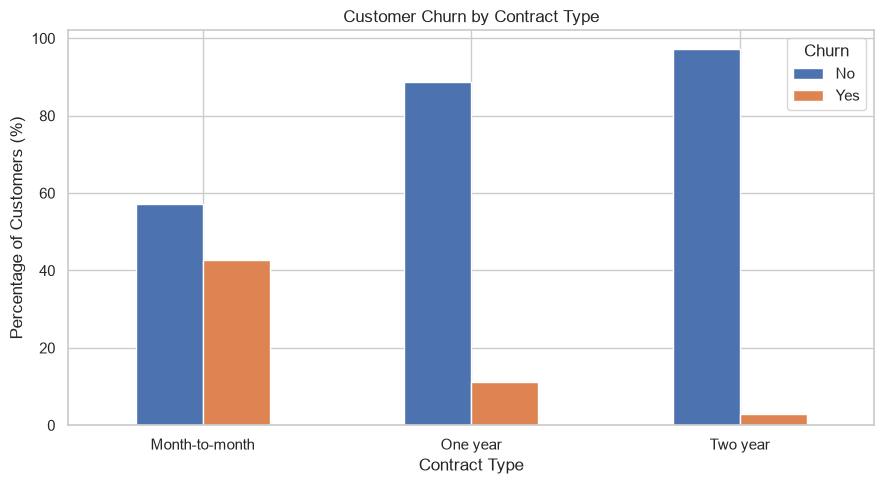

In [17]:
contract_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [19]:
contract_churn_rate = (
    df.groupby("Contract")["Churn_Binary"]
    .mean() * 100
).sort_values(ascending=False)

display(contract_churn_rate.to_frame("Churn Rate (%)"))

,Churn Rate (%)
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


In [20]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

display(internet_churn)

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


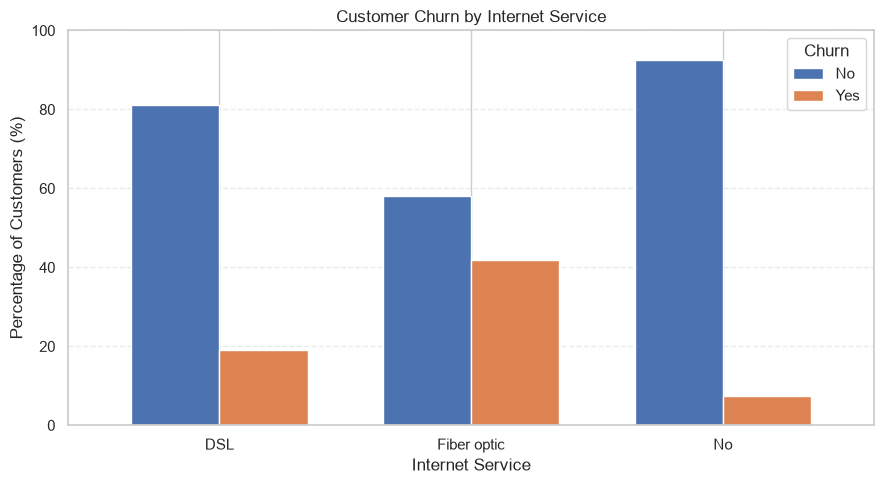

In [21]:
# Calculate churn percentage by internet service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

# Display percentage table
display(internet_churn)

# Visualize
internet_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [22]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

display(payment_churn)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


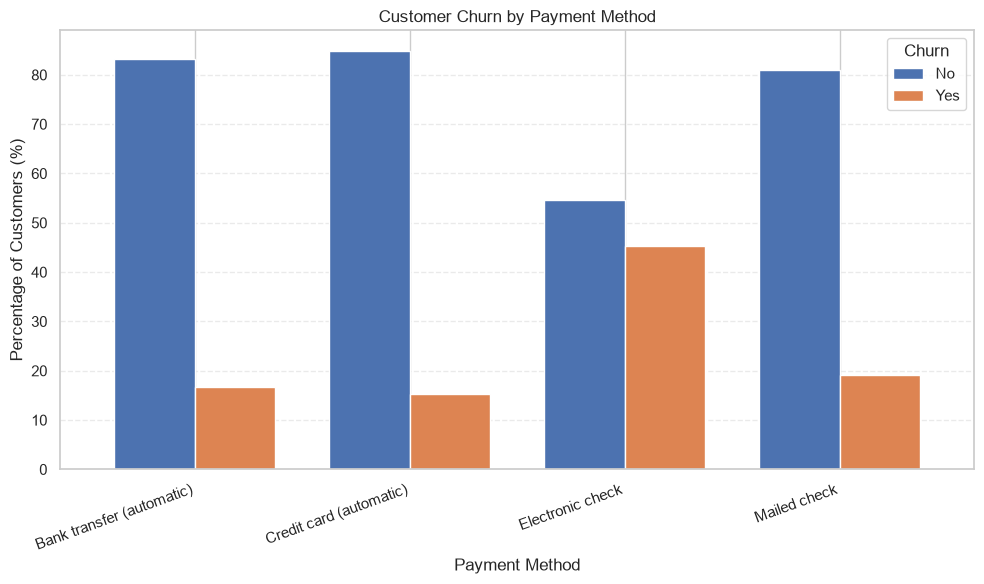

In [23]:
# Calculate churn percentage for each payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

display(payment_churn)

# Visualize the results
payment_churn.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Churn")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


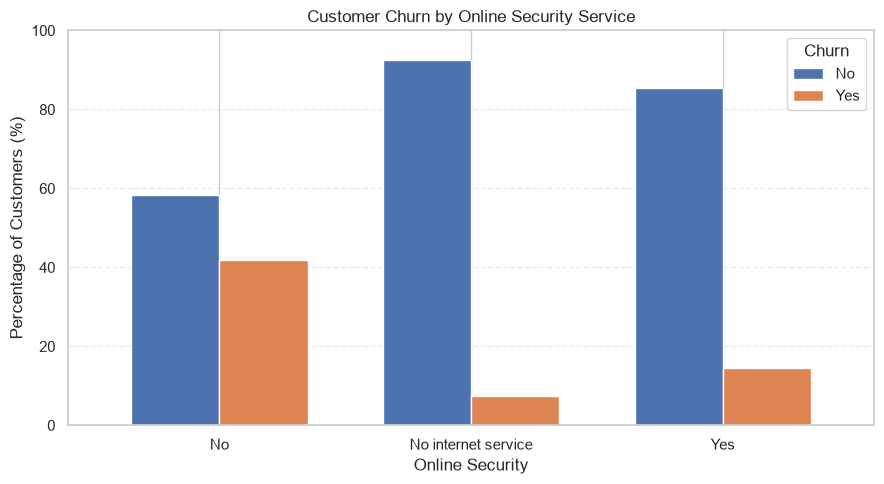

In [24]:
# Calculate churn percentage
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

display(security_churn)

# Visualize
security_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Online Security Service")
plt.xlabel("Online Security")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


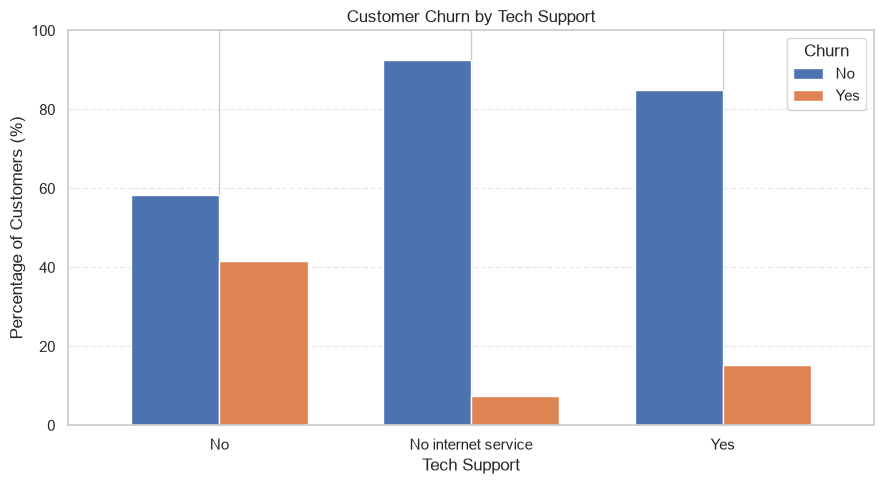

In [26]:
tech_support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

display(tech_support_churn)

# Visualization
tech_support_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

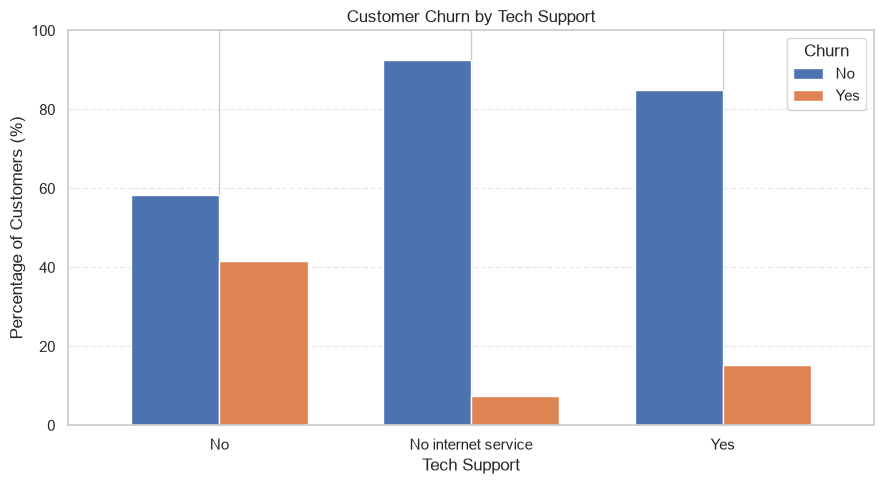

In [27]:
tech_support_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


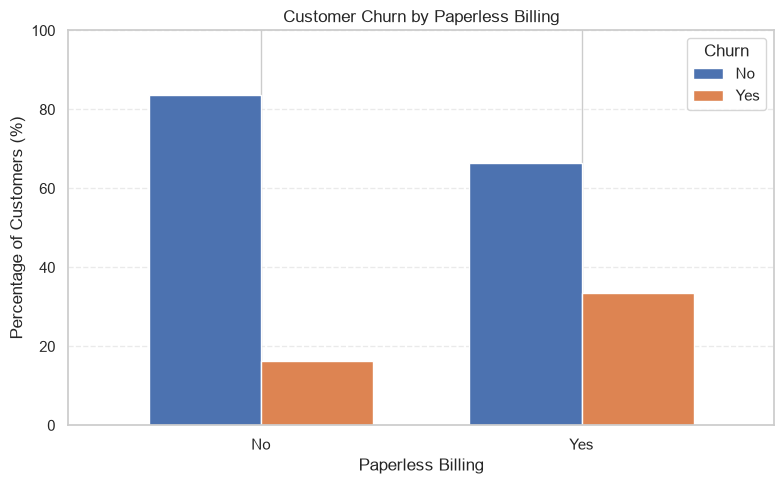

In [28]:
paperless_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

display(paperless_churn)

# Visualization
paperless_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


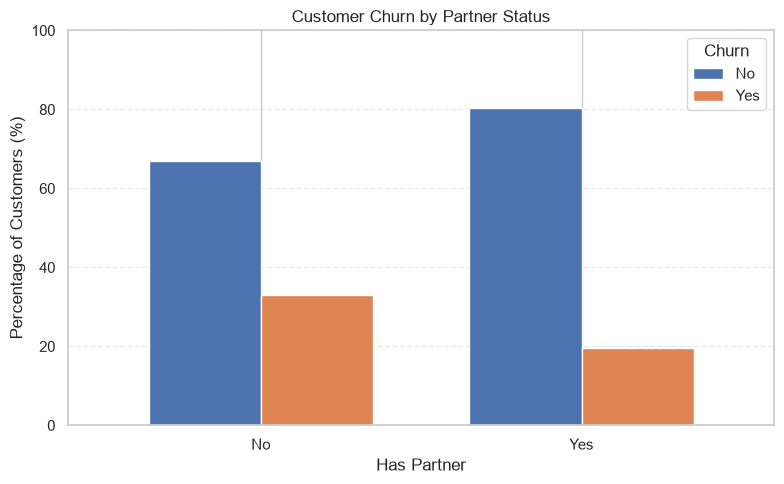

In [30]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

display(partner_churn)

# Visualization
partner_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


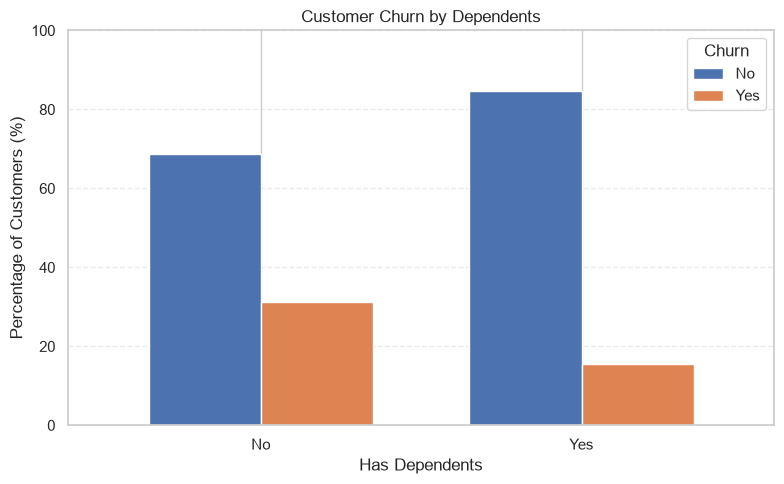

In [31]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

display(dependents_churn)

# Visualization
dependents_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Dependents")
plt.xlabel("Has Dependents")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


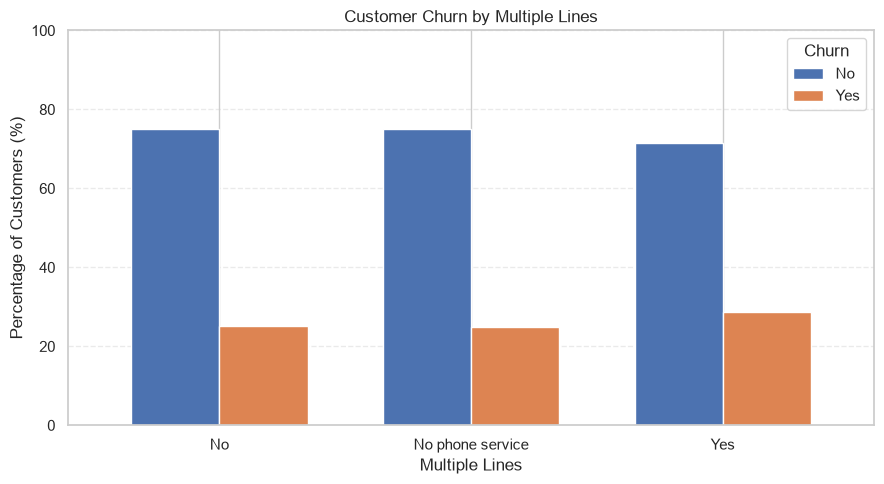

In [32]:
multiple_lines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

display(multiple_lines_churn)

# Visualization
multiple_lines_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


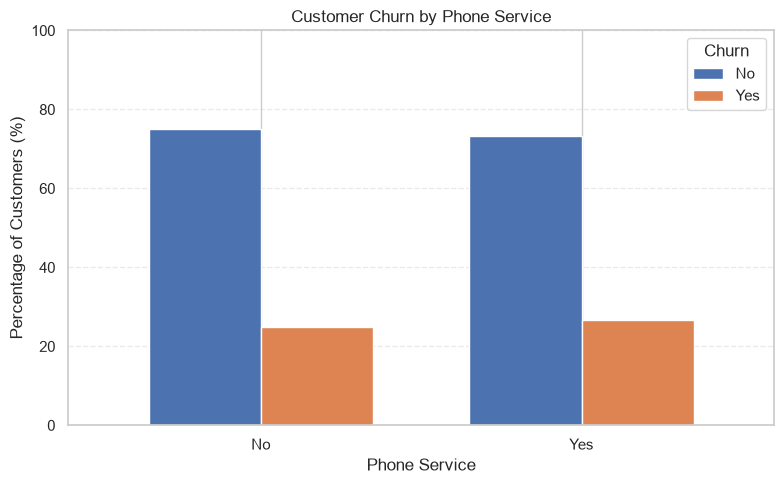

In [33]:
phone_churn = pd.crosstab(
    df["PhoneService"],
    df["Churn"],
    normalize="index"
) * 100

display(phone_churn)

# Visualization
phone_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


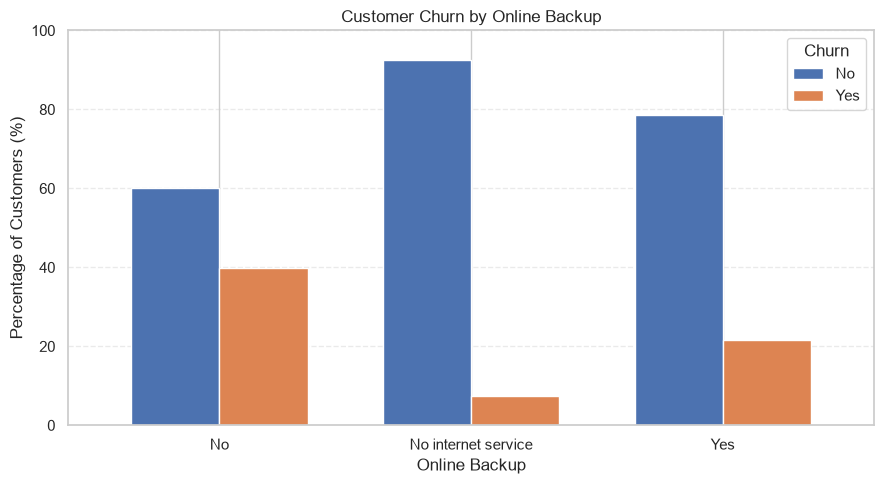

In [34]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

display(backup_churn)

# Visualization
backup_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


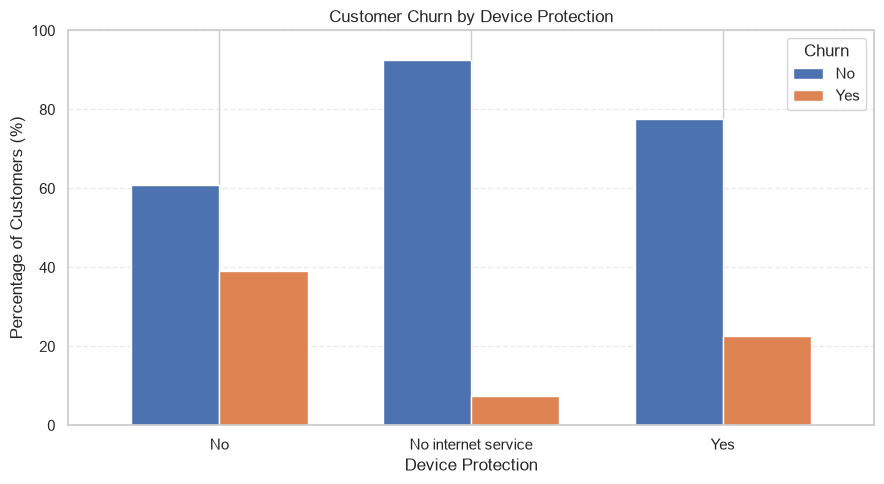

In [35]:
device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

display(device_churn)

# Visualization
device_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


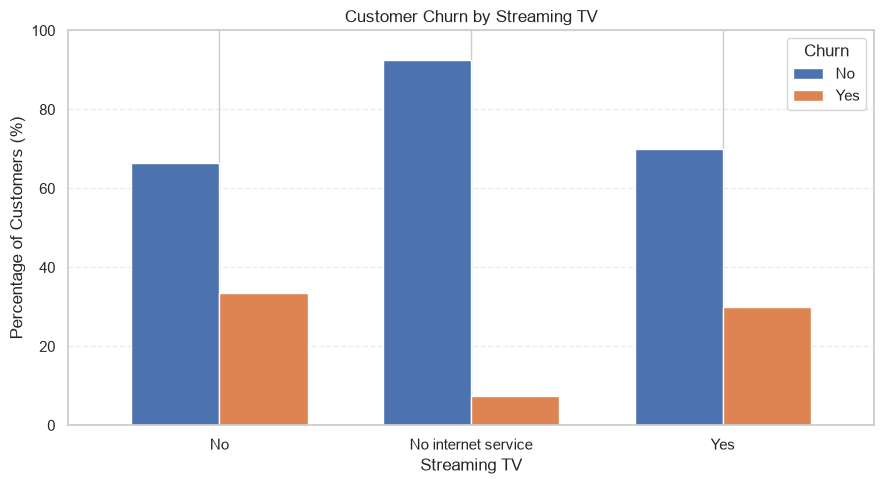

In [36]:
streaming_tv_churn = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

display(streaming_tv_churn)

# Visualization
streaming_tv_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


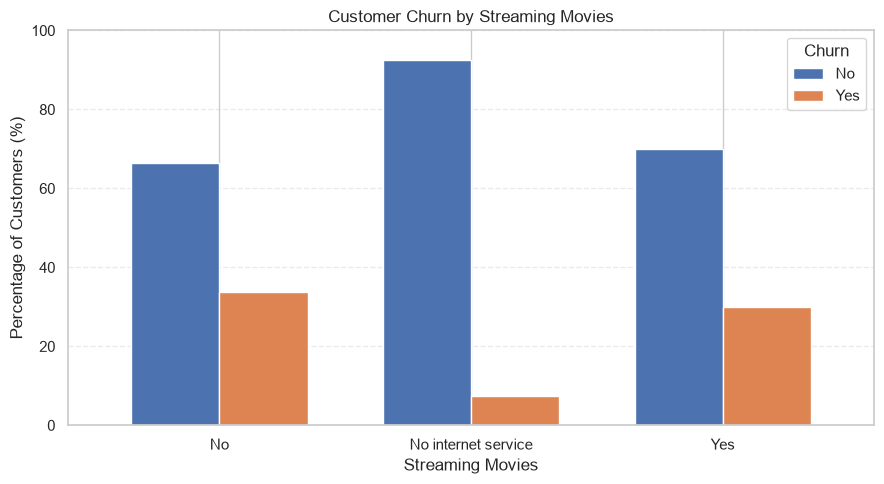

In [37]:
streaming_movies_churn = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

display(streaming_movies_churn)

# Visualization
streaming_movies_churn.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Customer Churn by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


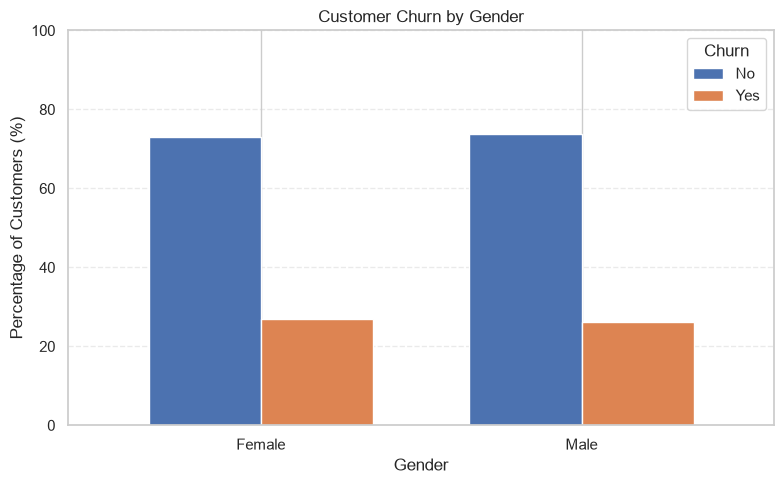

In [38]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

display(gender_churn)

# Visualization
gender_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


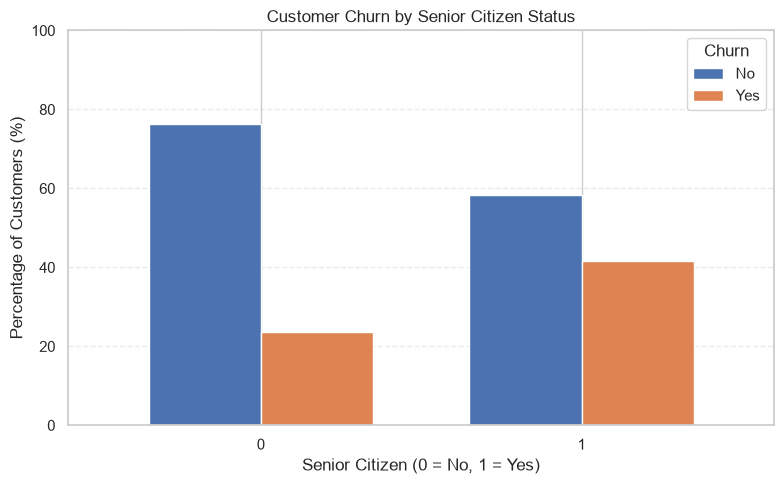

In [39]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

display(senior_churn)

# Visualization
senior_churn.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

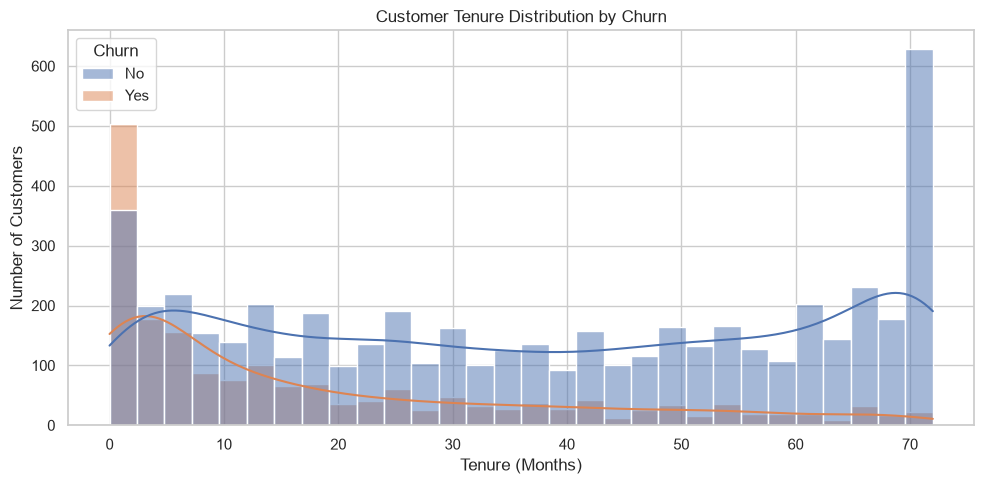

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    kde=True
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()